In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
plt.style.use('default')
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False 
import pickle
import jsonpickle
import tensorflow as tf
import json
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Conv1D,Conv2D,MaxPooling1D, MaxPooling2D, Flatten, Dense, Input, Dropout, LSTM, TimeDistributed, Reshape, BatchNormalization, Activation, concatenate
import shap
cm = 1/2.54
# 字号
fontsize = 8
seed = 2025

In [11]:
# 加载模型
model_cc = tf.keras.models.load_model(r'D:\My_program\long\code\8-explain\models\model_CC.h5')
model_cv = tf.keras.models.load_model(r'D:\My_program\long\code\8-explain\models\model_CV.h5')
model_re = tf.keras.models.load_model(r'D:\My_program\long\code\8-explain\models\model_RE.h5')

#### CC解释

In [12]:
# 加载数据
with open(r'D:\My_program\long\code\8-explain\data\CC_late.pkl', 'rb') as file:
    train_x1, train_x2, train_y, val_x1, val_x2, val_y, test_x1, test_x2, test_y = pickle.load(file)

In [13]:
train_x1 = train_x1.reshape(train_x1.shape[0], train_x1.shape[1], 1)
test_x1 = test_x1.reshape(test_x1.shape[0], test_x1.shape[1], 1)

In [14]:
# 使用shap.summary_plot可视化特征重要性
explainer = shap.DeepExplainer(model_cc, [train_x1[:500], train_x2[:500]])
shap_values_cc = explainer.shap_values([test_x1, test_x2])
expected_value_cc = explainer.expected_value
# 保存
with open(r'D:\My_program\long\code\8-explain\data\shap_values_cc.pkl', 'wb') as file:
    pickle.dump(shap_values_cc, file)
with open(r'D:\My_program\long\code\8-explain\data\expected_value_cc.pkl', 'wb') as file:
    pickle.dump(expected_value_cc, file)

Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


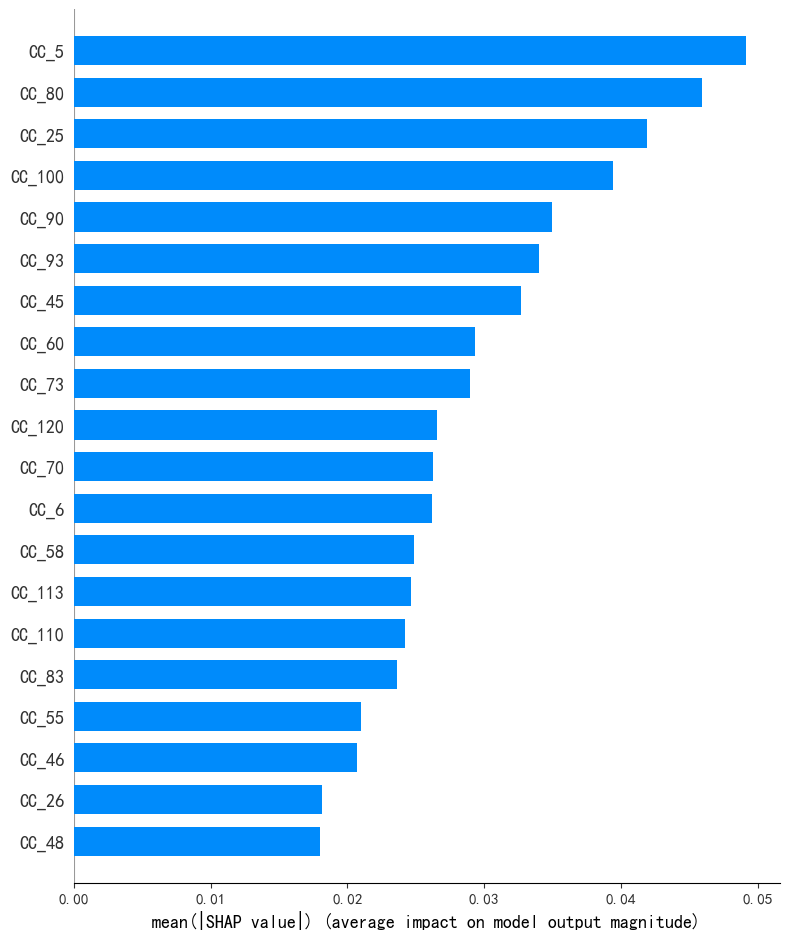

In [15]:
shap.summary_plot(shap_values_cc[0][0].reshape((4040, 151)), test_x1.reshape((4040, 151)), plot_type="bar", show=False,
                  feature_names=['CC_' + str(i) for i in range(151)])

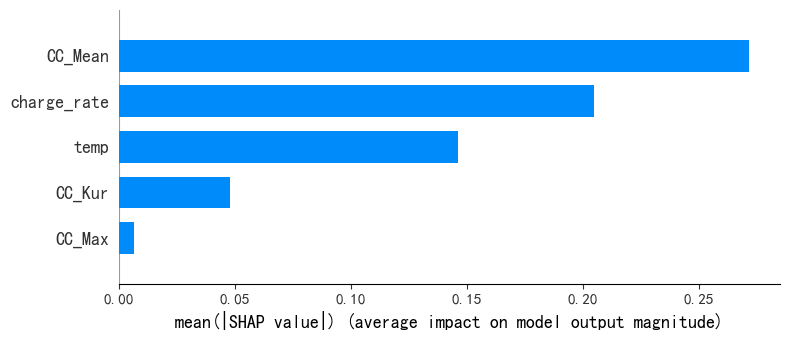

In [16]:
shap.summary_plot(shap_values_cc[0][1].reshape((4040, 5)), test_x2.reshape((4040, 5)), plot_type="bar", show=False,
                  feature_names=['temp', 'charge_rate', 'CC_Kur', 'CC_Max', 'CC_Mean'])

#### CV解释

In [17]:
# 加载数据
with open(r'D:\My_program\long\code\8-explain\data\CV_early.pkl', 'rb') as file:
    train_x, train_y, val_x, val_y, test_x, test_y = pickle.load(file)
    print(train_x.shape)

(13762, 156)


In [ ]:
# 使用shap.summary_plot可视化特征重要性
explainer = shap.Explainer(model_cv, train_x[:500])
shap_values_cv = explainer.shap_values(test_x)


In [19]:
# 保存
with open(r'D:\My_program\long\code\8-explain\data\shap_values_cv.pkl', 'wb') as file:
    pickle.dump(shap_values_cv, file)

4
(4040, 156)
(4040, 156)


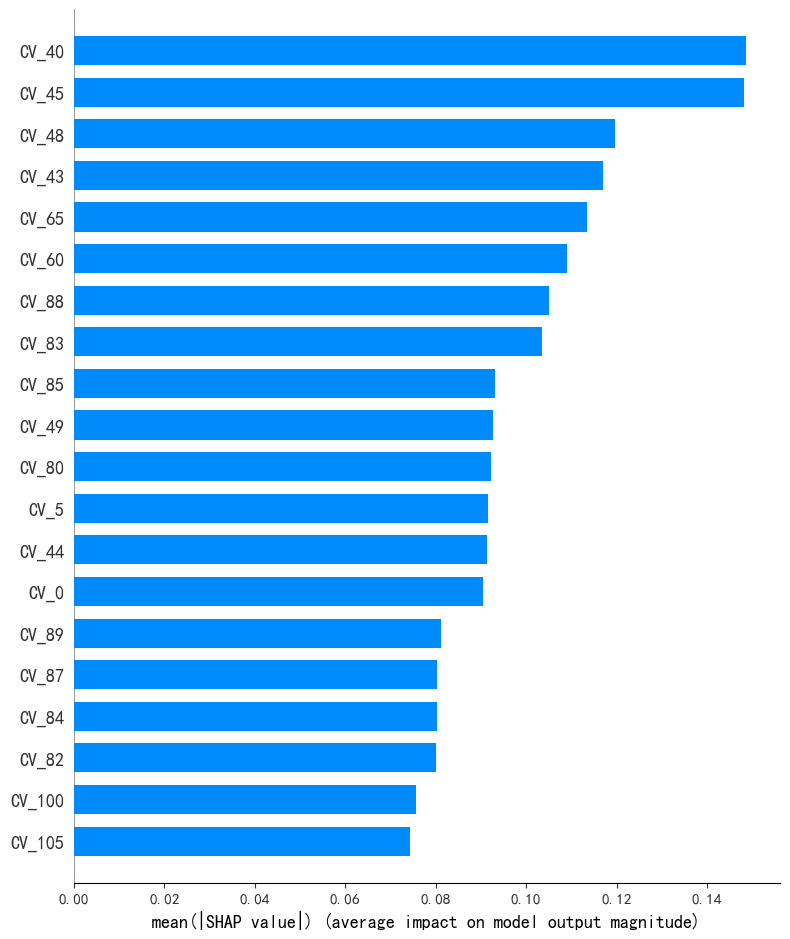

In [20]:
# 加载数据
with open(r'D:\My_program\long\code\8-explain\data\CV_early.pkl', 'rb') as file:
    train_x, train_y, val_x, val_y, test_x, test_y = pickle.load(file)
feature_names= ['CV_' + str(i) for i in range(151)]+['temp', 'charge_rate','CV_Kur', 'CV_Ske', 'CV_Min']
print(len(feature_names[0]))
print(test_x.shape)
print(shap_values_cv.shape)
shap.summary_plot(shap_values_cv, test_x, plot_type="bar", show=False, feature_names=feature_names)

#### RE解释

In [21]:
# 加载数据
with open(r'D:\My_program\long\code\8-explain\data\RE_late.pkl', 'rb') as file:
    train_x1, train_x2, train_y, val_x1, val_x2, val_y, test_x1, test_x2, test_y = pickle.load(file)

In [22]:
train_x1 = train_x1.reshape(train_x1.shape[0], train_x1.shape[1], 1)
test_x1 = test_x1.reshape(test_x1.shape[0], test_x1.shape[1], 1)

In [23]:
# 使用shap.summary_plot可视化特征重要性
explainer = shap.DeepExplainer(model_re, [train_x1[:500], train_x2[:500]])
shap_values_re = explainer.shap_values([test_x1, test_x2])
expected_value_re = explainer.expected_value
# 保存
with open(r'D:\My_program\long\code\8-explain\data\shap_values_re.pkl', 'wb') as file:
    pickle.dump(shap_values_re, file)
with open(r'D:\My_program\long\code\8-explain\data\expected_value_re.pkl', 'wb') as file:
    pickle.dump(expected_value_re, file)

Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


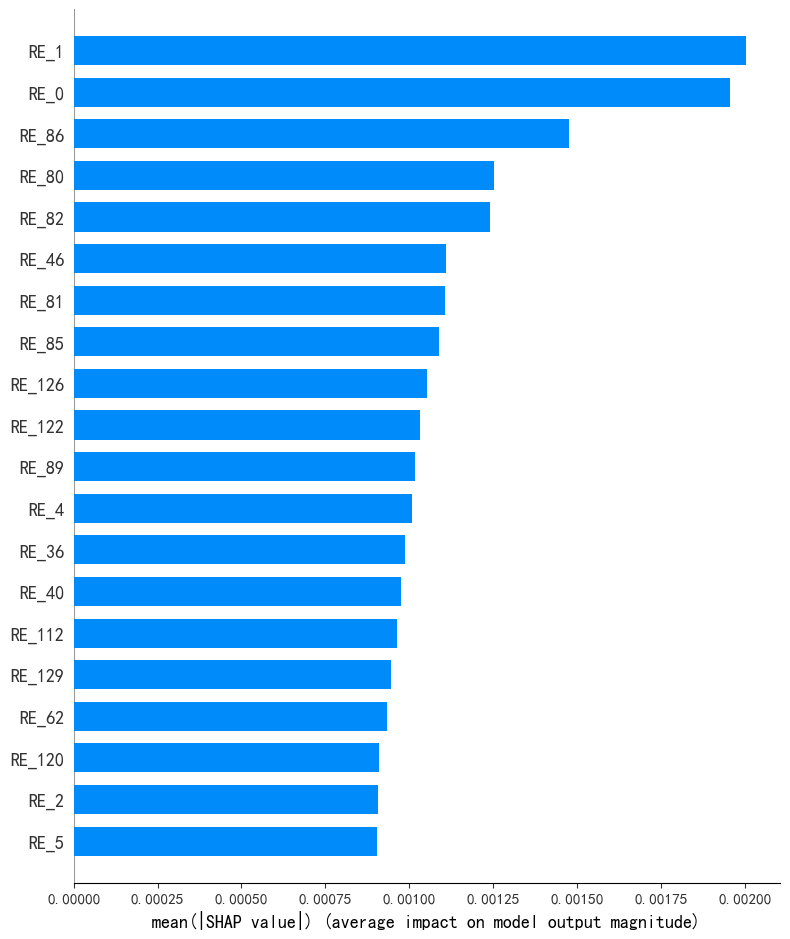

In [24]:
# 加载数据
with open(r'D:\My_program\long\code\8-explain\data\RE_late.pkl', 'rb') as file:
    train_x1, train_x2, train_y, val_x1, val_x2, val_y, test_x1, test_x2, test_y = pickle.load(file)
shap.summary_plot(shap_values_re[0][0].reshape((4040, 151)), test_x1.reshape((4040, 151)), plot_type="bar", show=False,
                  feature_names=['RE_' + str(i) for i in range(151)])


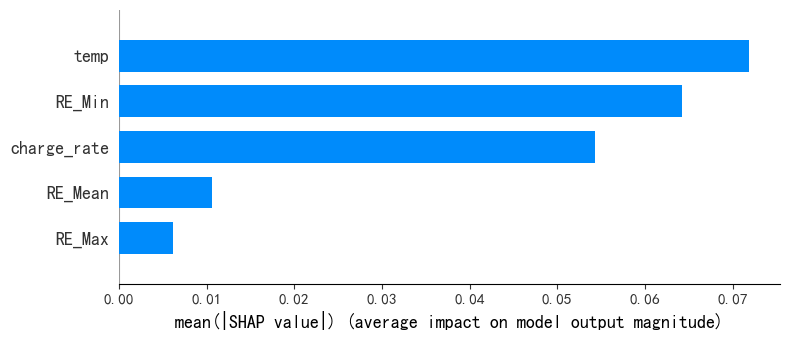

In [25]:
shap.summary_plot(shap_values_re[0][1].reshape((4040, 5)), test_x2.reshape((4040, 5)), plot_type="bar", show=False,
                  feature_names=['temp', 'charge_rate', 'RE_Mean', 'RE_Max', 'RE_Min'])